# Supply chain digital twin – CA_1, FOODS_3

Goal: stress-test the Phase 2 inventory policies in a supplier → DC → store network with
disruptions, using a discrete-event simulation in SimPy.

## How SimPy works: a toy model

One item, one store, one supplier. Demand is 10 units a day; every 7 days the store orders
up to 120 units; deliveries take `lead_time` days.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import simpy

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


def run_toy(
    days=42, demand=10, start_stock=50, order_up_to=120, lead_time=3, outage=None, verbose=True
):
    """One item, one store, one supplier. outage = (first_day, last_day) the supplier is down."""
    env = simpy.Environment()
    state = {"stock": start_stock, "on_order": 0}
    daily = []

    def say(event, units):
        if verbose:
            print(f"day {env.now:>3}: {event:<9} {units:>4} units   stock {state['stock']:>4}")

    def delivery(units):
        """A truck: wait while the supplier is down, then the lead time, then unload."""
        if outage and outage[0] <= env.now <= outage[1]:
            yield env.timeout(outage[1] + 1 - env.now)
        yield env.timeout(lead_time)
        state["stock"] += units
        state["on_order"] -= units
        say("delivered", units)

    def store():
        """Every day: on day 0, 7, 14... order up to `order_up_to`, then sell."""
        while True:
            if env.now % 7 == 0:
                units = max(0, order_up_to - state["stock"] - state["on_order"])
                if units:
                    state["on_order"] += units
                    say("ordered", units)
                    env.process(delivery(units))
            sold = min(state["stock"], demand)
            state["stock"] -= sold
            if sold < demand:
                say("lost", demand - sold)
            daily.append({"day": env.now, "stock": state["stock"], "lost": demand - sold})
            yield env.timeout(1)

    env.process(store())
    env.run(until=days)
    return pd.DataFrame(daily)

In [2]:
run_toy(days=15);

day   0: ordered     70 units   stock   50
day   3: delivered   70 units   stock   90
day   7: ordered     70 units   stock   50
day  10: delivered   70 units   stock   90
day  14: ordered     70 units   stock   50


day   0: ordered    120 units   stock   50
day   5: lost        10 units   stock    0
day   6: lost        10 units   stock    0
day   7: ordered     50 units   stock    0
day   7: lost        10 units   stock    0
day   8: lost        10 units   stock    0
day   9: delivered  120 units   stock  120
day  14: ordered     50 units   stock   70
day  16: delivered   50 units   stock  100
day  21: ordered     70 units   stock   50
day  23: delivered   50 units   stock   80
day  28: ordered     70 units   stock   30
day  30: delivered   70 units   stock   80
day  35: ordered     70 units   stock   30
day  37: delivered   70 units   stock   80


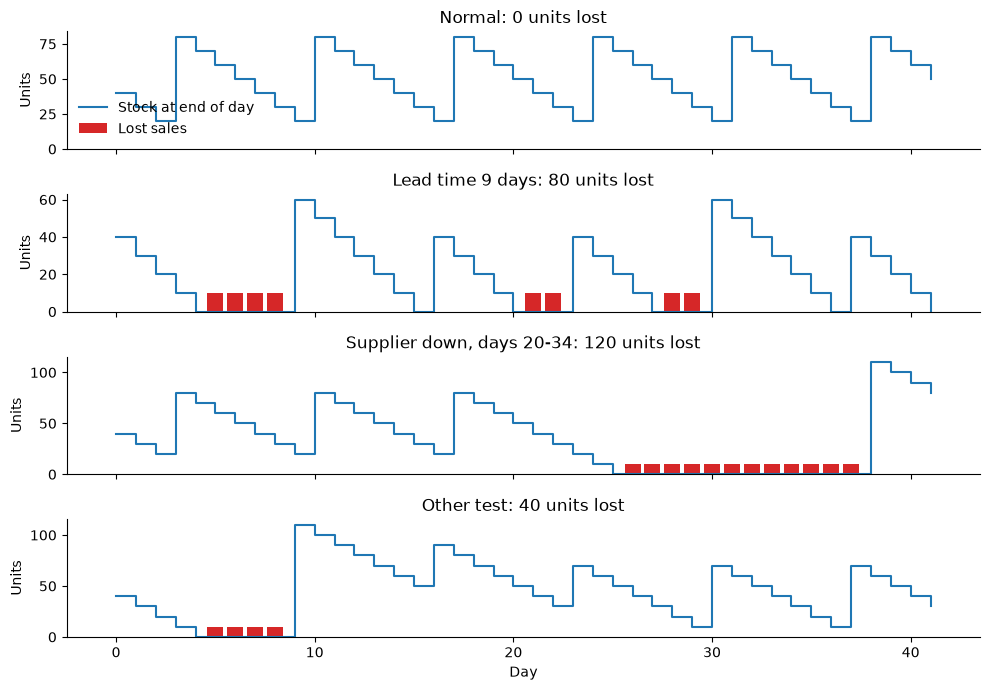

In [3]:
runs = {
    "Normal": run_toy(verbose=False),
    "Lead time 9 days": run_toy(lead_time=9, verbose=False),
    "Supplier down, days 20-34": run_toy(outage=(20, 34), verbose=False),
    "Other test": run_toy(order_up_to=170, lead_time=9),
}

fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for ax, (name, d) in zip(axes, runs.items()):
    ax.plot(d["day"], d["stock"], drawstyle="steps-post", label="Stock at end of day")
    ax.bar(d["day"], d["lost"], color="tab:red", label="Lost sales")
    ax.set_title(f"{name}: {d['lost'].sum()} units lost")
    ax.set_ylabel("Units")
axes[0].legend(frameon=False)
axes[-1].set_xlabel("Day")
plt.tight_layout()
plt.show()

## The twin under normal conditions

Check 1: with an unlimited DC, the twin reproduces the Phase 2 replay exactly
(see `tests/test_twin.py`). Check 2 (below): with a real DC and supplier, each store
policy loses less than 1 point of service.

In [4]:
import json
import sys
from functools import partial
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.inventory import policies
from src.inventory.inputs import build_inputs, draw_lead_times
from src.inventory.kpis import scorecard
from src.simulation.config import NetworkConfig
from src.simulation.dc import dc_order_up_to
from src.simulation.twin import Twin

inputs = build_inputs()
lead_times = draw_lead_times(inputs)
z_by_class = json.loads((ROOT / "results" / "inventory_z.json").read_text())

STORE_POLICIES = {
    "Weeks of cover": partial(policies.weeks_of_cover, weeks=3),
    "(R, S) normal": policies.order_up_to_normal,
    "(R, S) quantile": partial(policies.order_up_to_quantile, z_by_class=z_by_class),
    "(s, S)": partial(policies.reorder_point, z_by_class=z_by_class),
}

normal = {}
for name, policy in STORE_POLICIES.items():
    twin = Twin(inputs, policy, dc_order_up_to, lead_times, NetworkConfig()).run()
    normal[name] = scorecard(twin.store_records()).loc["all"]

pd.DataFrame(normal).T[["fill_rate", "cycle_service", "stock_value", "total_cost"]].round(3)

,fill_rate,cycle_service,stock_value,total_cost
Weeks of cover,0.957,0.906,76839.093,23852.264
"(R, S) normal",0.901,0.846,41207.859,36933.689
"(R, S) quantile",0.969,0.948,69941.350,25028.307
"(s, S)",0.983,0.977,119167.264,17192.044


## Disruption scenarios: one run each

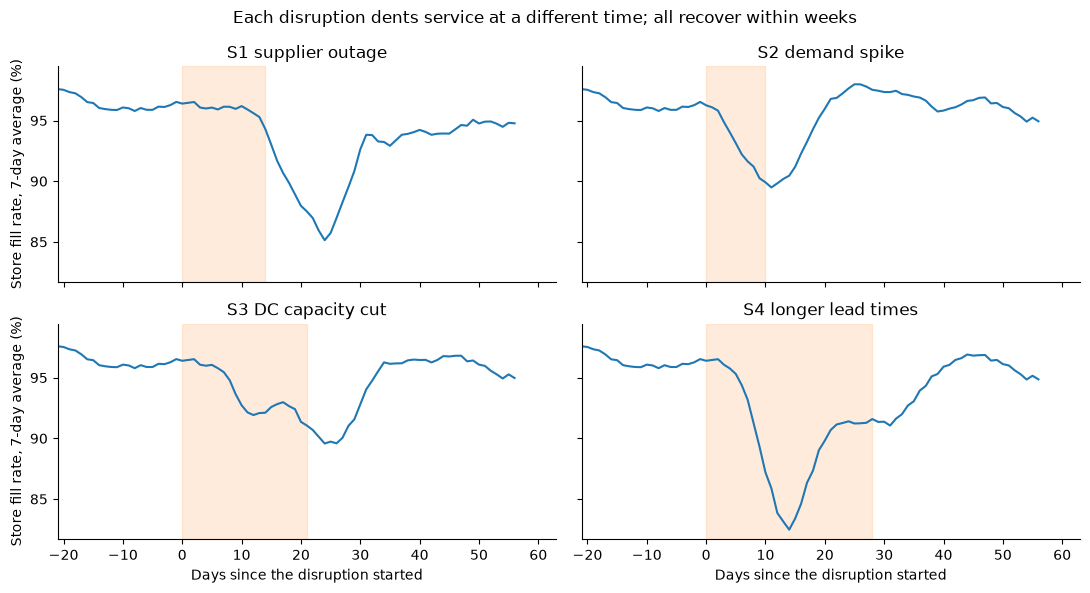

In [5]:
from src.simulation.scenarios import SCENARIOS, run_scenario

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
for ax, scenario in zip(axes.flat, list(SCENARIOS)[1:]):
    kpis, twin = run_scenario("(R, S) quantile", scenario, seed=0)
    s = twin.store_records()
    daily = s.groupby("ds")[["sales", "demand"]].sum()
    fill = (daily["sales"] / daily["demand"]).rolling(7).mean()
    days = pd.Series(range(len(fill)), index=fill.index) - kpis["start_day"]
    ax.axvspan(0, SCENARIOS[scenario][0], color="tab:orange", alpha=0.15)
    ax.plot(days, fill * 100)
    ax.set_title(scenario)
    ax.set_xlim(-21, 63)
for ax in axes[1]:
    ax.set_xlabel("Days since the disruption started")
for ax in axes[:, 0]:
    ax.set_ylabel("Store fill rate, 7-day average (%)")
fig.suptitle("Each disruption dents service at a different time; all recover within weeks")
plt.tight_layout()
plt.show()

## Policies across disruptions (20 runs each)

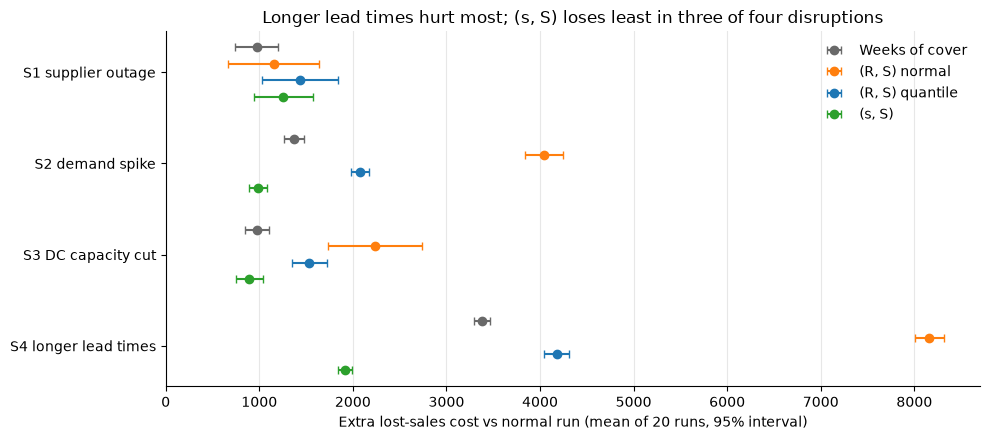

In [6]:
summary = pd.read_csv(ROOT / "results" / "twin_summary.csv")
daily = pd.read_csv(ROOT / "results" / "twin_daily.csv")

COLORS = {
    "Weeks of cover": "dimgray",
    "(R, S) normal": "tab:orange",
    "(R, S) quantile": "tab:blue",
    "(s, S)": "tab:green",
}
scenarios = [s for s in SCENARIOS if not s.startswith("S0")]

fig, ax = plt.subplots(figsize=(10, 4.5))
for j, (policy, color) in enumerate(COLORS.items()):
    rows = summary[summary["policy"] == policy].set_index("scenario").loc[scenarios]
    y = [i + (j - 1.5) * 0.18 for i in range(len(scenarios))]
    ax.errorbar(
        rows["extra_lost_cost"],
        y,
        xerr=rows["extra_lost_cost_ci"],
        fmt="o",
        color=color,
        capsize=3,
        label=policy,
    )
ax.set_yticks(range(len(scenarios)), scenarios)
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=0.3)
ax.set_xlabel("Extra lost-sales cost vs normal run (mean of 20 runs, 95% interval)")
ax.set_title("Longer lead times hurt most; (s, S) loses least in three of four disruptions")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
fig.savefig(ROOT / "docs" / "twin_lost_sales.png", dpi=150, bbox_inches="tight")
plt.show()

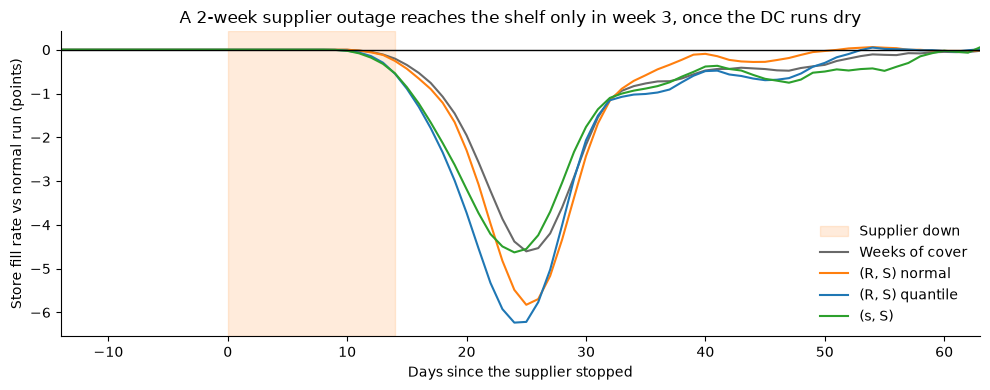

In [7]:
s1 = daily[daily["scenario"] == "S1 supplier outage"]
avg = s1.groupby(["policy", "day"])[["fill", "normal_fill"]].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(0, 14, color="tab:orange", alpha=0.15, label="Supplier down")
for policy, color in COLORS.items():
    g = avg[avg["policy"] == policy]
    ax.plot(g["day"], (g["fill"] - g["normal_fill"]) * 100, color=color, label=policy)
ax.axhline(0, color="black", linewidth=1)
ax.set_xlim(-14, 63)
ax.set_xlabel("Days since the supplier stopped")
ax.set_ylabel("Store fill rate vs normal run (points)")
ax.set_title("A 2-week supplier outage reaches the shelf only in week 3, once the DC runs dry")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## Mitigation: a bigger DC buffer for the A items

The top 20% of items by sales value get 99% service at the DC instead of 95%. Tested with (s, S) at the store, 20 seeds.

In [8]:
from src.simulation.mitigation import break_even

mitigation = pd.read_csv(ROOT / "results" / "twin_mitigation.csv")
cols = ["lost_sales_cost", "dc_holding_cost", "total_cost_with_dc"]
display(mitigation.groupby(["scenario", "mitigation"])[cols].mean().round(0))
break_even(mitigation).round(2)

lost_sales_cost  dc_holding_cost  \
scenario           mitigation                                        
S0 normal          A-item buffer           3280.0           7206.0   
                   No buffer               3347.0           6679.0   
S1 supplier outage A-item buffer           4412.0           6174.0   
                   No buffer               4605.0           5705.0   
S3 DC capacity cut A-item buffer           4174.0           7738.0   
                   No buffer               4239.0           7209.0   

                                  total_cost_with_dc  
scenario           mitigation                         
S0 normal          A-item buffer             24392.0  
                   No buffer                 23889.0  
S1 supplier outage A-item buffer             24251.0  
                   No buffer                 23905.0  
S3 DC capacity cut A-item buffer             25309.0  
                   No buffer                 24805.0

,scenario,damage_avoided_per_disruption,buffer_cost_per_year,break_even_disruptions_per_year
0,S1 supplier outage,156.2,1455.07,9.32
1,S3 DC capacity cut,-2.0,1455.07,NaN


## Findings

1. **The twin is trustworthy.** With an unlimited DC it reproduces the Phase 2 replay exactly; with a real, finite DC every policy loses under 1 point of service in normal times.
2. **(s, S) is the most robust policy.** It has the lowest extra lost sales in the demand spike, the DC capacity cut and the longer lead times, and it is the cheapest in every scenario including DC holding (23,900 in normal times vs 30,600–44,300 for the others).
3. **Longer lead times hurt most, and surprises hurt forecast policies.** S4 is the worst scenario for every policy. In the unforecast demand spike, (R, S) normal loses 4,041 in sales against 989 for (s, S).
4. **What did worse than expected: (s, S) pushes problems upstream.** Its batches leave the DC out of stock on 17% of item-days and raise the order variability from 0.17 at the store to 0.27 at the DC (bullwhip). It is also the slowest to recover from a supplier outage (44 days), and in S1 no policy is clearly better than the others.
5. **More DC stock is not worth it.** An A-item buffer costs 1,455 a year and saves 156 per 2-week supplier outage, so it pays only above 9.3 outages a year; in a DC capacity cut it saves nothing, because the bottleneck is handling, not stock.